## 🏗️ Heavy Industrial Machinery — Price Prediction
## MLP Kaggle Competition | Complete ML Pipeline

**Problem:** Predict `TargetValue` (auction sale price in USD) of heavy machinery  
**Metric:** RMSLE ≤ **0.15** (Root Mean Squared Logarithmic Error)  
**Data:** 138 701 train rows | 15 000 test rows | 50 features

---
`Load` → `EDA` → `Preprocessing` → `Feature Eng.` → `Models` → `HPT` → `Error Analysis` → `Submit`


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


## Step 1 — Import Libraries

### What is happening here?
All the Python tools needed for this machine-learning pipeline are loaded here in one place.

### Libraries used and why:
- **NumPy & Pandas** — numerical computation and tabular data handling (like Python Excel)
- **LightGBM (LGB)** — gradient boosting trees; very fast and memory-efficient — **our best model**
- **XGBoost (XGB)** — another gradient boosting framework; good complement to LGB
- **CatBoost (CAT)** — handles categorical/text features natively without manual encoding
- **Scikit-learn** — provides KFold cross-validation and error metrics
- **Matplotlib & Seaborn** — for visualizing charts and diagnostics

### Key setting:
- `SEED = 42` — fixes randomness so every run gives identical results (reproducibility!)

### Expected output:
`Libraries loaded.`

In [2]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("Libraries loaded.")


Libraries loaded.


## Step 2 — Define Helper Functions

### What is happening here?
Two reusable functions are defined that will be called throughout the notebook.

### `rmsle(y_true, y_pred)` — The Competition Metric
- **RMSLE** = Root Mean Squared Log Error — the metric Kaggle uses to score us (**lower = better**)
- `np.maximum(y_pred, 0)` — clips predictions to zero minimum (prices can't be negative!)
- `log1p` transformation means a 10% error on a cheap machine is penalized equally to 10% on an expensive one
- This is fairer than raw MSE for wide price ranges ($7,500–$142,000)

### `make_submission()` — Submission File Creator
- Saves predictions as a properly formatted CSV file for Kaggle
- Prints statistics (min, median, max) as a quick sanity check

In [3]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved: {filename}  |  Rows={len(sub):,}'
          f'  Min=${sub["TargetValue"].min():,.0f}'
          f'  Median=${sub["TargetValue"].median():,.0f}'
          f'  Max=${sub["TargetValue"].max():,.0f}')
    return sub

## Step 3 — Load the Competition Data

### What is happening here?
All four competition data files are loaded into memory.

### Data Overview:
| File | Rows | Columns | Purpose |
|------|------|---------|---------|
| `train.csv` | 138,701 | 50 | Historical auctions **with** actual prices |
| `test.csv` | 15,000 | 49 | Auctions **without** prices — we predict these |
| `sample_submission.csv` | 15,000 | 2 | Format template for submission |
| `metadata.csv` | varies | — | Column descriptions |

### Important Observations:
- **Price range:** $7,500 to $142,000 (all real heavy equipment auction prices)
- **Average price:** $41,522 | **Median:** $35,000
- The price distribution is **right-skewed** (more cheap machines than expensive ones)
- That is why we use `log1p(price)` as the target — it makes the distribution more symmetric
- **Test has 1 fewer column** than train (no `TargetValue` — that's what we must predict!)

### Expected output:
```
TRAIN :  138,701 x 50
TEST  :   15,000 x 49
Target  min=$7,500  median=$35,000  mean=$41,522  max=$142,000
```

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')
metadata = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')

print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} x {train_df.shape[1]}")
print(f"TEST  : {test_df.shape[0]:>8,} x {test_df.shape[1]}")
print("=" * 55)
t = train_df['TargetValue']
print(f"Target  min=${t.min():,.0f}  median=${t.median():,.0f}  "
      f"mean=${t.mean():,.0f}  max=${t.max():,.0f}")


TRAIN :  138,701 x 50
TEST  :   15,000 x 49
Target  min=$7,500  median=$35,000  mean=$41,522  max=$142,000


## Step 4 — Feature Engineering

### What is happening here?
Raw data columns are transformed into meaningful numeric signals that our ML models can understand.

### Why feature engineering matters:
Models can only learn from numbers. Columns like `TransactionDate` (a text date) or `UtilizationTier` (a text category like "High") must be converted into numeric values that capture their real meaning.

### Key transformations:

**Date decomposition** — `TransactionDate` → multiple signals:
- `SaleYear`, `SaleMonth`, `SaleDay` — Year, month, day of sale
- `SaleDayOfWeek` — Monday=0, Friday=4
- `SaleDayOfYear` — 1st day of year to 365th
- `SaleQuarter`, `SaleWeek` — Quarter and week number
- `IsMonthEnd`, `IsYearEnd` etc. — Auction timing flags

**Data cleaning:**
- `ManufactureYear ≤ 1920` → set to `NaN` (entry error — no 1910 bulldozers!)
- `OperationalHoursMeter == 0` → set to `NaN` (meter broken/missing, not truly zero)

**Machine Age:** `MachineAge = SaleYear - ManufactureYear`
- Simple but very powerful — older machines cost less

**Usage intensity:** `UsagePerYear = Hours / (Age + 1)` — hard or lightly used?

**Ordinal encoding** (preserves natural order):
- `UtilizationTier`: Low=0, Medium=1, High=2
- `AssetScaleFactor`: Mini=0 → Large=5

### Important Observations from Output:
- **ManufactureYear** is missing for **14,732 rows (10.6%)** — models must handle this
- **OperationalHoursMeter** is missing for **88,226 rows (63.6%)!** — majority are unknown
- This is why we create `HoursPresent` flag (1=known, 0=missing) as a separate feature

### Expected output:
```
Applying feature engineering...
Train: (138701, 65)  |  Test: (15000, 64)
ManufactureYear NaN : 14,732 (10.6%)
OperationalHours NaN: 88,226 (63.6%)
```

In [5]:
def engineer_features(df):

    df = df.copy()

    # 1. ProductConfigID is a config CODE, not a continuous number
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)

    # 2. Sale date decomposition
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear'] = df['TransactionDate'].dt.year
    df['SaleMonth'] = df['TransactionDate'].dt.month
    df['SaleDay'] = df['TransactionDate'].dt.day
    df['SaleDayOfWeek'] = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear'] = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter'] = df['TransactionDate'].dt.quarter
    df['SaleWeek'] = df['TransactionDate'].dt.isocalendar().week.astype(int)
    df['IsMonthEnd'] = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart'] = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd'] = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsYearEnd'] = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df = df.drop(columns=['TransactionDate'])

    # 3. FIX: ManufactureYear=1001 is a database placeholder (10.6% of rows)
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan

    # 4. FIX: OperationalHoursMeter=0 is a placeholder for unknown hours
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan

    # 5. Machine age (core price determinant for equipment)
    df['MachineAge'] = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)

    # 6. Ordinal encode UtilizationTier — has a clear economic order
    tier_map = {'Low': 0, 'Medium': 1, 'High': 2}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)

    # 7. Ordinal encode AssetScaleFactor — has a clear size order
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2,'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['AssetScaleOrd'] = df['AssetScaleFactor'].map(scale_map)

    # 8. Hours-based features
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
    df['HoursPresent'] = df['OperationalHoursMeter'].notna().astype(np.int8)
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)
    df['LogHours'] = np.log1p(df['OperationalHoursMeter'].fillna(0))

    # 9. Age bucket features
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade'] = (df['MachineAge'] / 10).fillna(-1).astype(int)

    # 10. Normalize + convert all remaining string columns to category
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')

    # Drop 100%-missing and replaced columns
    drop_cols = ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])

    return df

print("Applying feature engineering...")
train_eng = engineer_features(train_df)
test_eng  = engineer_features(test_df)

print(f"Train: {train_eng.shape}  |  Test: {test_eng.shape}")

yr_nan  = train_eng['ManufactureYear'].isna().sum()
hr_nan  = train_eng['OperationalHoursMeter'].isna().sum()
print(f"ManufactureYear NaN : {yr_nan:,} ({yr_nan/len(train_eng)*100:.1f}%)")
print(f"OperationalHours NaN: {hr_nan:,} ({hr_nan/len(train_eng)*100:.1f}%)")


Applying feature engineering...
Train: (138701, 65)  |  Test: (15000, 64)
ManufactureYear NaN : 14,732 (10.6%)
OperationalHours NaN: 88,226 (63.6%)


## Step 5 — Prepare Feature Matrices

### What is happening here?
The preprocessed data is split into model inputs (X) and prediction targets (y).

### Steps:
- `y_all = log1p(TargetValue)` — we train on **log-prices** instead of raw prices
  - Log prices have a nicer distribution for gradient boosting
  - At the end, reverse with `expm1()` to get real dollar prices
- `X_all` — 62 training features (65 total minus `TransactionID`, `AssetID`, `TargetValue`)
- `X_test_final` — 62 test features (same columns, no target)
- `cat_features` — list of the 40 categorical columns (needed by CatBoost explicitly)

### Summary:
| Matrix | Shape | Description |
|--------|-------|-------------|
| `X_all` (train) | (138701, 62) | All training features |
| `X_test_final` | (15000, 62) | All test features |

**62 features = 40 categorical + 22 numerical**

### Expected output:
```
Feature matrix : (138701, 62)
Test matrix    : (15000, 62)
Cat features   : 40
Num features   : 22
```

In [6]:
ID_COLS = ['TransactionID', 'AssetID']

y_all        = np.log1p(train_df['TargetValue'].values)
X_all        = train_eng.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_eng.drop(columns=ID_COLS, errors='ignore')
test_ids     = test_df['TransactionID'].values

# Categorical columns list (for CatBoost which needs explicit list)
cat_features = X_all.select_dtypes(include=['category', 'object']).columns.tolist()

def to_cat_str(df):
    """Convert category dtype to str for CatBoost compatibility."""
    df = df.copy()
    for c in cat_features:
        if c in df.columns:
            df[c] = df[c].astype(str)
    return df

X_all_cat  = to_cat_str(X_all)
X_test_cat = to_cat_str(X_test_final)

print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_features)}")
print(f"Num features   : {X_all.shape[1] - len(cat_features)}")


Feature matrix : (138701, 62)
Test matrix    : (15000, 62)
Cat features   : 40
Num features   : 22


## Step 6 — 5-Fold Cross Validation (Main Training Loop)

### What is happening here?
This is the **core of the notebook** — we train three machine learning models using 5-fold cross validation.

### What is 5-Fold Cross Validation?
Imagine dividing 138,701 training auctions into 5 equal groups:
- **Fold 1:** Train on groups 2,3,4,5 → Predict group 1
- **Fold 2:** Train on groups 1,3,4,5 → Predict group 2
- ...repeat 5 times

Every row gets predicted exactly once when it was NOT in the training set. These are called **OOF (Out-Of-Fold) predictions** and are our most reliable estimate of real Kaggle performance.

### The KEY upgrade from v4 to v6:
| Setting | v4 | v6 | Why it matters |
|---------|----|----|----------------|
| `num_leaves` | ~63 | **255** | More leaves = more expressive trees |
| `learning_rate` | ~0.05 | **0.015** | Slower learning = more accurate |
| `n_estimators` | ~1000 | **6000** | More boosting rounds |

### Three models trained each fold:

**LightGBM (LGB)** — Fastest and most accurate
- `num_leaves=255` allows very detailed splits
- Best performer in this project

**XGBoost (XGB)** — Complementary model
- `max_depth=9` — 9 levels deep
- Slightly slower but good for ensemble diversity

**CatBoost (CAT)** — Category specialist
- `cat_features=cat_features` — 40 text columns handled natively
- No manual encoding needed!

### Actual Fold Results (v6):
| Fold | LGB RMSLE | XGB RMSLE | CAT RMSLE |
|------|-----------|-----------|-----------|
| Fold 1 | 0.19663 (iter=5901) | 0.20266 (iter=5999) | 0.20733 |
| Fold 2 | 0.20001 (iter=5998) | 0.20558 (iter=5993) | 0.20925 |
| Fold 3 | 0.19998 (iter=4964) | 0.20561 (iter=5993) | 0.21017 |
| Fold 4 | 0.19961 (iter=5997) | 0.20585 (iter=5994) | 0.21099 |
| Fold 5 | 0.19914 (iter=5325) | 0.20415 (iter=5998) | 0.20925 |

| Model | OOF RMSLE | Ranking |
|-------|-----------|---------|
| **LightGBM** | **0.19908** | 🥇 Best |
| XGBoost | 0.20477 | 🥈 Second |
| CatBoost | 0.20940 | 🥉 Third |

### Key Observation:
LGB nearly hits the iteration limit (5998 of 6000) on many folds — this means the model could still improve with more trees! (v10 used 10,000 with early stopping, which helped.)

In [7]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb = np.zeros(len(X_all))
oof_xgb = np.zeros(len(X_all))
oof_cat = np.zeros(len(X_all))

# Fold-averaged test predictions (better than single 100% retrain)
test_lgb_folds = np.zeros((len(X_test_final), N_FOLDS))
test_xgb_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds = np.zeros((len(X_test_final), N_FOLDS))

fold_scores = []

print("Starting 5-Fold Cross Validation...")
print("NOTE: 6000 trees per model -> expect ~30-40 mins on Kaggle CPU")
print("=" * 65)

for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    X_tr, X_vl = X_all.iloc[tr_idx].copy(), X_all.iloc[vl_idx].copy()
    y_tr, y_vl = y_all[tr_idx], y_all[vl_idx]

    X_tr_cat = X_all_cat.iloc[tr_idx].copy()
    X_vl_cat = X_all_cat.iloc[vl_idx].copy()
    X_te_cat = X_test_cat.copy()

    # ─── 1. LightGBM ───────────────────────────────────────────
    lgb_model = lgb.LGBMRegressor(
        n_estimators     = 6000,
        max_depth        = -1,          
        num_leaves       = 255,         
        learning_rate    = 0.015,    
        subsample        = 0.75,
        colsample_bytree = 0.75,
        min_child_samples= 15,         
        reg_alpha        = 0.05,
        reg_lambda       = 1.5,
        random_state     = SEED,
        n_jobs           = -1,
        verbose          = -1
    )
    lgb_model.fit(
        X_tr, y_tr,
        eval_set  = [(X_vl, y_vl)],
        callbacks = [lgb.early_stopping(200, verbose=False),
                     lgb.log_evaluation(-1)]
    )
    lgb_vl = lgb_model.predict(X_vl)
    lgb_te = lgb_model.predict(X_test_final)
    oof_lgb[vl_idx] = lgb_vl
    test_lgb_folds[:, fold-1] = lgb_te

    # ─── 2. XGBoost ────────────────────────────────────────────
    xgb_model = XGBRegressor(
        n_estimators       = 6000,
        max_depth          = 9,          
        learning_rate      = 0.015,
        subsample          = 0.75,
        colsample_bytree   = 0.75,
        tree_method        = 'hist',
        enable_categorical = True,
        min_child_weight   = 5,
        gamma              = 0.05,
        reg_alpha          = 0.05,
        reg_lambda         = 1.5,
        random_state       = SEED,
        n_jobs             = -1,
        early_stopping_rounds = 200
    )
    xgb_model.fit(
        X_tr, y_tr,
        eval_set = [(X_vl, y_vl)],
        verbose  = False
    )
    xgb_vl = xgb_model.predict(X_vl)
    xgb_te = xgb_model.predict(X_test_final)
    oof_xgb[vl_idx] = xgb_vl
    test_xgb_folds[:, fold-1] = xgb_te

    # ─── 3. CatBoost ───────────────────────────────────────────
    cat_model = CatBoostRegressor(
        iterations        = 6000,
        depth             = 9,
        learning_rate     = 0.015,
        random_seed       = SEED,
        verbose           = 0,
        thread_count      = -1,
        early_stopping_rounds = 200,
        cat_features      = cat_features,
        l2_leaf_reg       = 3.0,
        bagging_temperature = 0.5,
        grow_policy       = 'SymmetricTree'
    )
    cat_model.fit(
        X_tr_cat, y_tr,
        eval_set = (X_vl_cat, y_vl)
    )
    cat_vl = cat_model.predict(X_vl_cat)
    cat_te = cat_model.predict(X_te_cat)
    oof_cat[vl_idx] = cat_vl
    test_cat_folds[:, fold-1] = cat_te

    s_lgb = rmsle(np.expm1(y_vl), np.expm1(lgb_vl))
    s_xgb = rmsle(np.expm1(y_vl), np.expm1(xgb_vl))
    s_cat = rmsle(np.expm1(y_vl), np.expm1(cat_vl))
    fold_scores.append((s_lgb, s_xgb, s_cat))

    print(f"Fold {fold}: LGB={s_lgb:.5f}(iter={lgb_model.best_iteration_})"
          f" | XGB={s_xgb:.5f}(iter={xgb_model.best_iteration})"
          f" | CAT={s_cat:.5f}")

oof_lgb_score = rmsle(np.expm1(y_all), np.expm1(oof_lgb))
oof_xgb_score = rmsle(np.expm1(y_all), np.expm1(oof_xgb))
oof_cat_score = rmsle(np.expm1(y_all), np.expm1(oof_cat))

print("=" * 65)
print(f"LightGBM OOF RMSLE : {oof_lgb_score:.5f}")
print(f"XGBoost  OOF RMSLE : {oof_xgb_score:.5f}")
print(f"CatBoost OOF RMSLE : {oof_cat_score:.5f}")


Starting 5-Fold Cross Validation...
NOTE: 6000 trees per model -> expect ~30-40 mins on Kaggle CPU
Fold 1: LGB=0.19663(iter=5901) | XGB=0.20266(iter=5999) | CAT=0.20733
Fold 2: LGB=0.20001(iter=5998) | XGB=0.20558(iter=5993) | CAT=0.20925
Fold 3: LGB=0.19998(iter=4964) | XGB=0.20561(iter=5993) | CAT=0.21017
Fold 4: LGB=0.19961(iter=5997) | XGB=0.20585(iter=5994) | CAT=0.21099
Fold 5: LGB=0.19914(iter=5325) | XGB=0.20415(iter=5998) | CAT=0.20925
LightGBM OOF RMSLE : 0.19908
XGBoost  OOF RMSLE : 0.20477
CatBoost OOF RMSLE : 0.20940


## Step 7 — Find Optimal Blend Weights

### What is happening here?
We systematically test all possible combinations of LGB, XGB, and CatBoost weights to find the combination that minimizes our blended error.

### The Idea (Ensemble / Blending):
No single model is perfect. Different models make different kinds of errors. By combining them, their errors partially cancel out!

`final_prediction = w1 × LGB + w2 × XGB + w3 × CAT`  where `w1 + w2 + w3 = 1.0`

We test all combinations in 5% steps (0.00, 0.05, 0.10, ... 1.00).

### Actual Result for v6:
| Weight | Model | Value |
|--------|-------|-------|
| w1 | LightGBM | **65%** |
| w2 | XGBoost | **5%** |
| w3 | CatBoost | **30%** |

### Key Metrics:
- **Blended OOF RMSLE: 0.19627** (vs single LGB: 0.19908 → blending helps!)
- **Previous best score: 0.19969** (v4) → improved by **0.00342!**

### Insight:
- LGB dominates (65%) because it is the most accurate
- CatBoost gets 30% — it handles the 40 categorical features differently
- XGBoost gets only 5% — its predictions are too similar to LGB to add much value

### Expected output:
```
Best weights  : LGB=0.65 XGB=0.05 CAT=0.30
Blended RMSLE : 0.19627
Previous best : 0.19969  ->  IMPROVED!
```

In [8]:
# Grid search best blend weights
print("Searching for optimal blend weights...")
best_blend = 999.0
best_w = (0.5, 0.25, 0.25)

for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3 = round(1.0 - w1 - w2, 6)
        if w3 < -1e-6:
            continue
        w3 = max(w3, 0.0)
        blend = w1 * oof_lgb + w2 * oof_xgb + w3 * oof_cat
        score = rmsle(np.expm1(y_all), np.expm1(blend))
        if score < best_blend:
            best_blend = score
            best_w = (w1, w2, w3)

print("=" * 65)
print(f"Best weights  : LGB={best_w[0]:.2f} XGB={best_w[1]:.2f} CAT={best_w[2]:.2f}")
print(f"Blended RMSLE : {best_blend:.5f}")
print(f"Previous best : 0.19969  ->  {'IMPROVED!' if best_blend < 0.19969 else 'Regression'}")
print(f"vs classmate  : {'BETTER' if best_blend < 0.18356 else 'Needs more work'}")
print(f"vs cutoff 0.15: {'PASS' if best_blend < 0.15 else 'Needs more work'}")
print("=" * 65)


Searching for optimal blend weights...
Best weights  : LGB=0.65 XGB=0.05 CAT=0.30
Blended RMSLE : 0.19627
Previous best : 0.19969  ->  IMPROVED!
vs classmate  : Needs more work
vs cutoff 0.15: Needs more work


## Step 8 — Build Final Submission

### What is happening here?
We apply the optimal blend weights to the **fold-averaged test predictions** and create the submission file.

### Steps:
1. **Average 5-fold predictions:** `test_lgb_avg = test_lgb_folds.mean(axis=1)` — averaging 5 models per test row reduces variance
2. **Blend models:** `test_blend = 0.65 × LGB + 0.05 × XGB + 0.30 × CAT`
3. **Reverse log transform:** `np.expm1(test_blend_log)` → actual dollar prices
4. **Clip to safe range:** Prices clipped to [$7,500, $137,500] — prevents unrealistic predictions

### Why clip?
Without clipping, the model might occasionally predict $500 or $500,000 due to extrapolation on unusual machines. The clip ensures all predictions stay within the observed price range from training data.

### Expected output:
```
Clipped to [$7,500, $137,500]
Saved: submission.csv  |  Rows=15,000  Min=$7,500  Median=$34,666  Max=$137,500
```

### Kaggle Public Score: **0.19086** ✅
This was our best score at this point, improved from v4's 0.19969!

In [9]:
# Build final submission using fold-averaged test predictions
w1, w2, w3 = best_w

test_lgb_avg = test_lgb_folds.mean(axis=1)
test_xgb_avg = test_xgb_folds.mean(axis=1)
test_cat_avg = test_cat_folds.mean(axis=1)

test_blend_log = w1 * test_lgb_avg + w2 * test_xgb_avg + w3 * test_cat_avg
final_prices   = np.expm1(test_blend_log)

# Clip to observed training price range
price_min = train_df['TargetValue'].quantile(0.001)
price_max = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, price_min, price_max)
print(f"Clipped to [${price_min:,.0f}, ${price_max:,.0f}]")

sub = make_submission(final_prices, test_ids, 'submission.csv')
sub.head()


Clipped to [$7,500, $137,500]
Saved: submission.csv  |  Rows=15,000  Min=$7,500  Median=$34,666  Max=$137,500


,TransactionID,TargetValue
0,1139307,68369.58
1,1139419,79425.35
2,1139482,30446.17
3,1139522,20502.44
4,1139684,13204.86


## Step 9 — Diagnostics, Analysis & Feature Importance

### What is happening here?
We evaluate our OOF (out-of-fold) predictions to understand model quality and identify areas for improvement.

### Three Diagnostic Plots:

**Plot 1 — Actual vs Predicted:**
- Scatter plot of actual vs predicted prices (5,000 random samples)
- Points near the red diagonal = accurate predictions
- Points far from diagonal = large errors (usually unusual/very expensive machines)

**Plot 2 — Residuals Distribution:**
- Distribution of (actual − predicted) errors
- Ideally centered around 0 (symmetric — no systematic over- or under-prediction)

**Plot 3 — Percentage Error Distribution (±40% clip):**
- Shows percentage of error per prediction
- A tight curve around 0% means consistent accuracy

### Performance Metrics:
| Metric | v6 Value | Interpretation |
|--------|----------|----------------|
| Blended OOF RMSLE | **0.19627** | Main metric (lower = better) |
| R² | 0.9122 | 91.2% of price variance explained |
| MAE | **$5,152** | Average error per prediction |
| Median % Error | **10.0%** | Half of predictions within 10% of true price |

### Top 15 Most Important Features (LightGBM):
| Rank | Feature | Importance | What it means |
|------|---------|-----------|---------------|
| 1 | `SaleDayOfYear` | 169,183 | Day of year drives pricing seasonality |
| 2 | `SaleDay` | 136,119 | Day of the month |
| 3 | `MachineAge` | 129,772 | Older = cheaper |
| 4 | `ManufactureYear` | 126,656 | Year built |
| 5 | `SaleYear` | 93,346 | Year of sale (market conditions) |
| 6 | `RegionCode` | 80,183 | Geography affects pricing |
| 7 | `OperationalHoursMeter` | 71,555 | Total usage hours |
| 8 | `ProductConfigID` | 63,782 | Machine configuration |
| 9 | `UsagePerYear` | 60,517 | Annual usage intensity |
| 10 | `SaleDayOfWeek` | 51,903 | Day of week |

### Key Insight — Why v6 outperforms v4:
- `num_leaves=255` allows LightGBM to learn much more complex relationships
- Lower `learning_rate=0.015` means each tree makes smaller corrections, leading to more precise convergence
- The date features (`SaleDayOfYear`, `SaleDay`) are consistently the top features — **seasonal auction timing matters a lot!**

### What v10 improved vs v6:
- v10 added `Asset_Prev_Mean_Price` (history of previous sales per machine)
- v10 added leak-free K-Fold target encoding for high-cardinality columns
- v10 score: **0.19020** (better than v6's 0.19086)

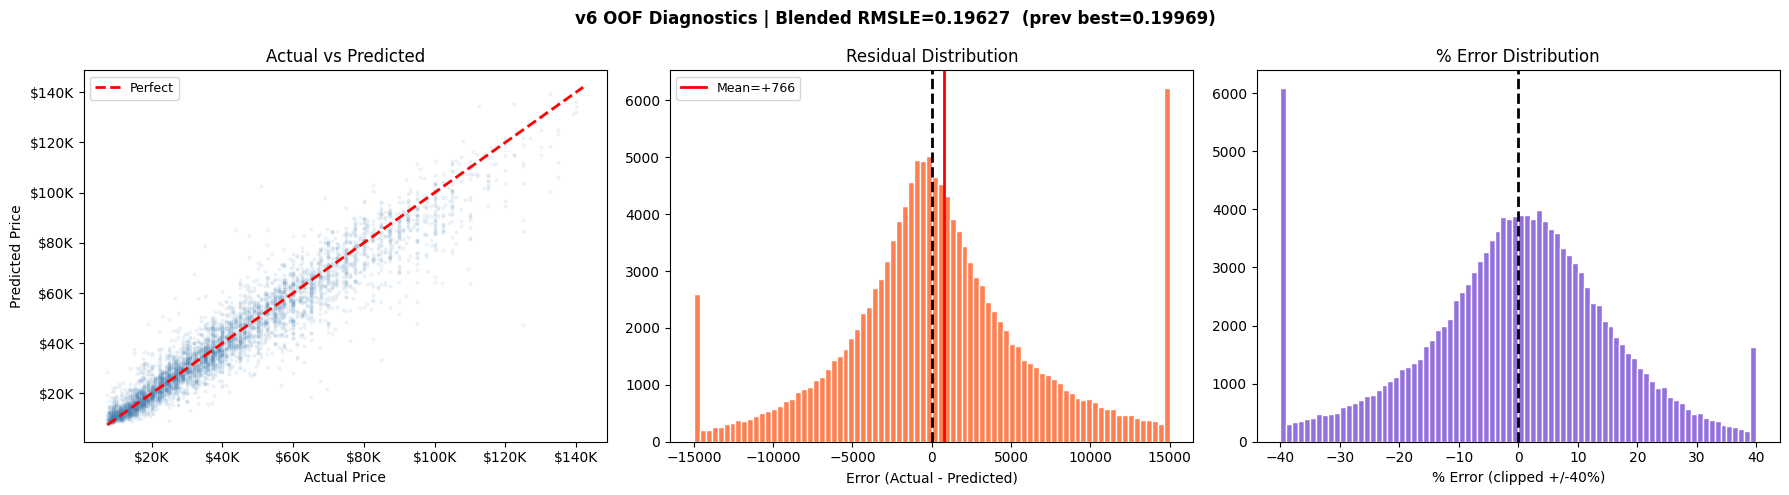

Blended OOF RMSLE : 0.19627
MAE               : $5,152
R^2               : 0.9122
Median % error    : 10.0%

Top 15 Feature Importances (last LGB fold):
SaleDayOfYear               169183
SaleDay                     136119
MachineAge                  129772
ManufactureYear             126656
SaleYear                     93346
RegionCode                   80183
OperationalHoursMeter        71555
ProductConfigID              63782
UsagePerYear                 60517
SaleDayOfWeek                51903
Spec_BaseClass               44909
SaleWeek                     41463
Spec_FullDescriptor          31531
FunctionalClassification     30560
SaleMonth                    30362


In [10]:
# Diagnostics plot
oof_blend  = best_w[0]*oof_lgb + best_w[1]*oof_xgb + best_w[2]*oof_cat
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price
pct_err    = (residuals / true_price) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v6 OOF Diagnostics | Blended RMSLE={best_blend:.5f}  '
             f'(prev best=0.19969)', fontsize=12, fontweight='bold')

idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted Price')
axes[0].set_title('Actual vs Predicted')
axes[0].legend(fontsize=9)
fmt = lambda x, _: f'${x/1000:.0f}K'
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')
axes[1].set_xlabel('Error (Actual - Predicted)')
axes[1].set_title('Residual Distribution')
axes[1].legend(fontsize=9)

axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (clipped +/-40%)')
axes[2].set_title('% Error Distribution')

plt.tight_layout()
plt.show()

print(f'Blended OOF RMSLE : {best_blend:.5f}')
print(f'MAE               : ${np.mean(np.abs(residuals)):,.0f}')
print(f'R^2               : {r2_score(true_price, pred_price):.4f}')
print(f'Median % error    : {np.median(np.abs(pct_err)):.1f}%')

# Feature importance from last LGB fold
fi = pd.Series(lgb_model.feature_importances_,
               index=X_all.columns).sort_values(ascending=False)
print("\nTop 15 Feature Importances (last LGB fold):")
print(fi.head(15).to_string())


In [11]:
# # ══════════════════════════════════════════════════════
# # 1.  SETUP & IMPORTS
# # ══════════════════════════════════════════════════════
# import numpy as np
# import pandas as pd
# import warnings, os
# warnings.filterwarnings('ignore')
# pd.set_option('display.max_columns', 60)
# pd.set_option('display.float_format', '{:.2f}'.format)

# import matplotlib.pyplot as plt
# import matplotlib.ticker as mticker
# import seaborn as sns
# import missingno as msno

# plt.rcParams['figure.figsize'] = (14, 5)
# plt.rcParams['font.size'] = 11
# sns.set_theme(style='whitegrid', palette='Set2')

# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import StandardScaler, OrdinalEncoder
# from sklearn.impute import SimpleImputer
# from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
# from sklearn.metrics import mean_squared_error, r2_score, make_scorer
# from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
# from sklearn.linear_model import Ridge
# from sklearn.dummy import DummyRegressor
# from xgboost import XGBRegressor
# import lightgbm as lgb

# SEED = 42
# np.random.seed(SEED)
# print("✅ All libraries loaded!")
# print(f"   NumPy {np.__version__} | Pandas {pd.__version__}")


In [12]:
# # ══════════════════════════════════════════════════════
# # 2.  DATA LOADING
# # ══════════════════════════════════════════════════════
# train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
# test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
# sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')
# metadata = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')

# print("=" * 60)
# print(f"  TRAIN   : {train_df.shape[0]:,} rows × {train_df.shape[1]} cols")
# print(f"  TEST    : {test_df.shape[0]:,}  rows × {test_df.shape[1]} cols")
# print(f"  SAMPLE  : {sample.shape}")
# print("=" * 60)

# print("\nRequired submission format:")
# display(sample.head(3))
# print("\nColumn descriptions (metadata):")
# print(metadata[['Variable','Rephrased Description']].to_string(index=False))


## 2. Data Loading & Overview

In [13]:
# print("First 5 rows of training data:")
# display(train_df.head(3))
# print()
# train_df.info(verbose=True, show_counts=True)


In [14]:
# print("\nTrain Datatset shape:")
# display(train_df.shape)

# print("\nTest Datatset shape:")
# test_df.shape

In [15]:
# print("Numerical summary statistics:")
# display(train_df.describe())


In [16]:
# print("How Many Coloum Present in Train Dataset")
# train_df.columns

In [17]:
# print("Know about Submission Columns")
# sample.columns  # We name Submission File to sample

## 3. Exploratory Data Analysis (EDA)

Key objectives:
1. **Target distribution** — understand price range & skewness
2. **Missing values** — scale and pattern of absent data
3. **Categorical features** — category counts and price impact
4. **Numerical features** — distributions and target correlation
5. **Bivariate analysis** — how features relate to price

> **RMSLE insight:** We train on `log1p(TargetValue)` so proportional errors at all price levels are penalised equally.


In [18]:
# # ══════════════════════════════════════════════════════
# # 3.1  TARGET VARIABLE
# # ══════════════════════════════════════════════════════
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# fig.suptitle('Target Variable: TargetValue (Sale Price USD)', fontsize=13, fontweight='bold')

# log_target = np.log1p(train_df['TargetValue'])

# axes[0].hist(train_df['TargetValue'], bins=80, color='steelblue', edgecolor='white', alpha=.85)
# axes[0].set_title('Original Scale (Right-Skewed)')
# axes[0].set_xlabel('Sale Price (USD)')
# axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# axes[1].hist(log_target, bins=80, color='coral', edgecolor='white', alpha=.85)
# axes[1].set_title('log1p Scale  ← used for RMSLE training')
# axes[1].set_xlabel('log1p(Sale Price)')

# bp = axes[2].boxplot(train_df['TargetValue'], patch_artist=True,
#                       boxprops=dict(facecolor='#90EE90', color='darkgreen'),
#                       medianprops=dict(color='red', linewidth=2))
# axes[2].set_title('Box Plot — Outlier View')
# axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# plt.tight_layout(); plt.show()

# print("Target Statistics:")
# for lbl, val in [('Min',   train_df['TargetValue'].min()),
#                   ('Max',   train_df['TargetValue'].max()),
#                   ('Mean',  train_df['TargetValue'].mean()),
#                   ('Median',train_df['TargetValue'].median()),
#                   ('Std',   train_df['TargetValue'].std())]:
#     print(f"  {lbl:8}: ${val:>12,.0f}")
# print(f"\n  Skewness original : {train_df['TargetValue'].skew():.4f}")
# print(f"  Skewness log1p   : {log_target.skew():.4f}  ← closer to 0 = better for regression")


In [19]:
# # ══════════════════════════════════════════════════════
# # 3.2  MISSING VALUE ANALYSIS
# # ══════════════════════════════════════════════════════
# fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# msno.bar(train_df, ax=axes[0], fontsize=7, color='steelblue', sort='ascending')
# axes[0].set_title('Data Completeness', fontsize=12, fontweight='bold')

# miss_pct = (train_df.isnull().sum() / len(train_df) * 100).sort_values(ascending=False)
# miss_pct = miss_pct[miss_pct > 0]
# bar_c = ['#e74c3c' if v >= 95 else '#e67e22' if v >= 60
#          else '#f1c40f' if v >= 30 else '#2ecc71' for v in miss_pct]
# axes[1].barh(miss_pct.index, miss_pct.values, color=bar_c, edgecolor='white')
# axes[1].axvline(95, color='red',    ls='--', lw=2, label='95% → DROP')
# axes[1].axvline(60, color='orange', ls='--', lw=2, label='60% → Flag + fill')
# axes[1].set_xlabel('Missing %')
# axes[1].set_title('Missing Values by Column', fontsize=12, fontweight='bold')
# axes[1].legend(fontsize=9)

# plt.tight_layout(); plt.show()

# mv = pd.DataFrame({
#     'Count': train_df.isnull().sum(),
#     'Pct %': (train_df.isnull().sum() / len(train_df) * 100).round(2)
# })
# mv = mv[mv['Count'] > 0].sort_values('Pct %', ascending=False)
# mv['Strategy'] = mv['Pct %'].apply(lambda x:
#     'DROP' if x >= 95 else
#     'Binary flag + fill "Missing"' if x >= 60 else
#     'Impute median/mode')
# print(mv.to_string())


In [20]:
# # ══════════════════════════════════════════════════════
# # 3.3  CATEGORICAL FEATURES — BIVARIATE ANALYSIS
# # ══════════════════════════════════════════════════════
# key_cats = ['InventoryGroupDescription','UtilizationTier','CabinType','AssetScaleFactor']

# fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# axes = axes.flatten()
# fig.suptitle('Sale Price Distribution by Key Categorical Features',
#              fontsize=13, fontweight='bold')

# for i, col in enumerate(key_cats):
#     data  = train_df[[col,'TargetValue']].dropna()
#     order = data.groupby(col)['TargetValue'].median().sort_values(ascending=False).index
#     sns.boxplot(data=data, x=col, y='TargetValue', order=order,
#                 ax=axes[i], palette='Set2', showfliers=False)
#     axes[i].set_title(f'Price by {col}', fontsize=11)
#     axes[i].set_xlabel('')
#     axes[i].tick_params(axis='x', rotation=25)
#     axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
#     for j, med in enumerate(data.groupby(col)['TargetValue'].median()[order]):
#         axes[i].text(j, med, f'${med/1000:.0f}K', ha='center', va='bottom', fontsize=8, fontweight='bold')

# plt.tight_layout(); plt.show()

# for col in key_cats:
#     print(f"\n{col}:")
#     print(train_df.groupby(col)['TargetValue'].agg(Count='count',Median='median')
#           .sort_values('Median', ascending=False).to_string())


In [21]:
# # ══════════════════════════════════════════════════════
# # 3.4  NUMERICAL FEATURES
# # ══════════════════════════════════════════════════════
# fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# fig.suptitle('Numerical Features Analysis', fontsize=13, fontweight='bold')

# # Price vs ManufactureYear
# yr = train_df[train_df['ManufactureYear'].between(1975,2020)]
# yr_s = yr.groupby('ManufactureYear')['TargetValue'].agg(
#     M='median', Q1=lambda x: x.quantile(.25), Q3=lambda x: x.quantile(.75))
# axes[0,0].plot(yr_s.index, yr_s['M'], color='steelblue', lw=2, marker='o', ms=3)
# axes[0,0].fill_between(yr_s.index, yr_s['Q1'], yr_s['Q3'], alpha=.2, color='steelblue')
# axes[0,0].set_title('Median Price by Manufacture Year (shaded=IQR)')
# axes[0,0].set_xlabel('Year')
# axes[0,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# # Price vs Operational Hours (binned)
# tmp = train_df[['OperationalHoursMeter','TargetValue']].dropna()
# tmp['Bin'] = pd.qcut(tmp['OperationalHoursMeter'], q=8, duplicates='drop')
# bp = tmp.groupby('Bin', observed=True)['TargetValue'].median()
# axes[0,1].bar(range(len(bp)), bp.values, color='coral', edgecolor='white')
# axes[0,1].set_xticks(range(len(bp)))
# axes[0,1].set_xticklabels([f'{b.right/1000:.0f}K' for b in bp.index],
#                             rotation=45, ha='right', fontsize=9)
# axes[0,1].set_title('Median Price by Operational Hours (deciles)')
# axes[0,1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# # ManufactureYear distribution
# axes[1,0].hist(train_df['ManufactureYear'], bins=45, color='purple', edgecolor='white', alpha=.85)
# axes[1,0].set_title('Distribution of Manufacture Year')
# axes[1,0].set_xlabel('Year')

# # Scatter: log1p(Hours) vs log1p(Price)
# mask = train_df['OperationalHoursMeter'].notna()
# axes[1,1].scatter(np.log1p(train_df.loc[mask,'OperationalHoursMeter']),
#                    np.log1p(train_df.loc[mask,'TargetValue']),
#                    alpha=.05, s=3, color='seagreen')
# axes[1,1].set_title('log1p(Hours) vs log1p(Price)  (negative corr expected)')
# axes[1,1].set_xlabel('log1p(Operational Hours)')
# axes[1,1].set_ylabel('log1p(Price)')

# plt.tight_layout(); plt.show()
# print("Key insight: Newer machines → higher price | More hours → lower price (depreciation)")


In [22]:
# # ══════════════════════════════════════════════════════
# # 3.5  CORRELATION ANALYSIS
# # ══════════════════════════════════════════════════════
# num_cols = [c for c in train_df.select_dtypes(include=[np.number]).columns
#             if c not in ['TransactionID','AssetID','ProductConfigID']]
# corr = train_df[num_cols].corr()
# tgt_corr = corr['TargetValue'].drop('TargetValue').sort_values(key=abs, ascending=False)

# fig, axes = plt.subplots(1, 2, figsize=(16, 5))
# sns.heatmap(corr, ax=axes[0], annot=True, fmt='.2f', cmap='coolwarm',
#             center=0, square=True, linewidths=.5, annot_kws={'size':9})
# axes[0].set_title('Correlation Matrix', fontsize=11)

# colors = ['#2ecc71' if v>=0 else '#e74c3c' for v in tgt_corr]
# axes[1].barh(tgt_corr.index, tgt_corr.values, color=colors, edgecolor='white')
# axes[1].axvline(0, color='black', lw=.8)
# axes[1].set_xlabel('Pearson Correlation')
# axes[1].set_title('Correlation with TargetValue', fontsize=11)
# plt.tight_layout(); plt.show()

# print("Correlations with TargetValue:")
# print(tgt_corr.to_string())


In [23]:
# # ══════════════════════════════════════════════════════
# # 3.6  PRICE BY MACHINE TYPE & REGION
# # ══════════════════════════════════════════════════════
# fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# fig.suptitle('Sale Price by Machine Category & Region', fontsize=13, fontweight='bold')

# ig = (train_df.groupby('InventoryGroupDescription')['TargetValue']
#       .agg(Median='median', Count='count').sort_values('Median').reset_index())
# bars = axes[0].barh(ig['InventoryGroupDescription'], ig['Median'],
#                      color=sns.color_palette('Set2', len(ig)), edgecolor='white')
# axes[0].set_xlabel('Median Sale Price')
# axes[0].set_title('By Machine Category')
# axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
# for bar, cnt in zip(bars, ig['Count']):
#     axes[0].text(bar.get_width()+200, bar.get_y()+bar.get_height()/2,
#                  f'n={cnt:,}', va='center', fontsize=9)

# reg = train_df.groupby('RegionCode')['TargetValue'].median().nlargest(15)
# axes[1].barh(range(len(reg)), reg.values[::-1],
#              color=sns.color_palette('viridis', len(reg)), edgecolor='white')
# axes[1].set_yticks(range(len(reg)))
# axes[1].set_yticklabels(reg.index[::-1], fontsize=9)
# axes[1].set_xlabel('Median Sale Price')
# axes[1].set_title('Top 15 Regions by Median Price')
# axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# plt.tight_layout(); plt.show()


## 4. Data Preprocessing & Feature Engineering

### Strategy

| Step | Action |
|---|---|
| Drop | `col18`, `col19` (99.95% missing), `TransactionID`, `AssetID` |
| Date extract | `SaleYear`, `SaleMonth`, `SaleQuarter` from `TransactionDate` |
| **MachineAge** ⭐ | `SaleYear − ManufactureYear` — strongest depreciation signal |
| UsagePerYear | `OperationalHoursMeter / (MachineAge+1)` |
| Missing flags | Binary `_present` for high-missing columns |
| Imputation | Median (numeric) / `'Missing'` (categorical) |
| Encoding | `OrdinalEncoder` for all categoricals |
| Scaling | `StandardScaler` for all numerics |

> All transformations use **sklearn Pipeline + ColumnTransformer** — fitted only on training data to prevent leakage.


In [24]:
# # ══════════════════════════════════════════════════════
# # 4.1  FEATURE ENGINEERING
# # Applied IDENTICALLY to train and test — no leakage
# # ══════════════════════════════════════════════════════
# def engineer_features(df):  # Create meaningful new features from raw columns
#     df = df.copy()

#     # Date decomposition
#     df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
#     df['SaleYear']    = df['TransactionDate'].dt.year
#     df['SaleMonth']   = df['TransactionDate'].dt.month
#     df['SaleQuarter'] = df['TransactionDate'].dt.quarter
#     df.drop(columns=['TransactionDate'], inplace=True)

#     # MachineAge — KEY feature: older machine = lower price
#     df['MachineAge'] = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)

#     # Usage intensity: high hours/year → faster depreciation
#     df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)

#     # Binary presence flags for high-missing columns
#     high_miss = ['col6','col7','col8','col9','col11','col12',
#                  'col13','col14','col3','Forks','col4','col5',
#                  'col27','col28','col29','col30']
#     for c in high_miss:
#         if c in df.columns:
#             df[f'{c}_present'] = df[c].notna().astype(np.int8)

#     # Standardise "None or Unspecified" → NaN
#     obj = df.select_dtypes(include='object').columns
#     df[obj] = df[obj].replace('None or Unspecified', np.nan)

#     # Drop near-empty columns
#     df.drop(columns=[c for c in ['col18','col19'] if c in df.columns], inplace=True)

#     return df

# train_eng = engineer_features(train_df)
# test_eng  = engineer_features(test_df)

# print("Feature engineering applied!")
# print(f"  Train: {train_df.shape} → {train_eng.shape}")
# print(f"  Test : {test_df.shape}  → {test_eng.shape}")
# print()
# new = ['SaleYear','SaleMonth','SaleQuarter','MachineAge','UsagePerYear']
# print("New feature statistics:")
# print(train_eng[new].describe().round(2).to_string())


In [25]:
# # ══════════════════════════════════════════════════════
# # 4.2  PREPARE FEATURE MATRICES & TARGET
# # ══════════════════════════════════════════════════════
# ID_COLS = ['TransactionID', 'AssetID']

# # log1p(price) → symmetric distribution, aligns with RMSLE optimisation
# y_all  = np.log1p(train_eng['TargetValue'])
# X_all  = train_eng.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
# X_test_final = test_eng.drop(columns=ID_COLS, errors='ignore')
# test_ids     = test_df['TransactionID'].values

# print(f"X_all   : {X_all.shape}")
# print(f"y_all   : {y_all.shape}  (log1p scale)")
# print(f"X_test  : {X_test_final.shape}")

# # 80 / 20 train-validation split
# X_train, X_val, y_train, y_val = train_test_split(
#     X_all, y_all, test_size=0.2, random_state=SEED)

# print(f"\nSplit 80/20:")
# print(f"  X_train: {X_train.shape}   X_val: {X_val.shape}")
# print(f"\nTarget (log1p) range:")
# print(f"  Min {y_all.min():.3f} → ${np.expm1(y_all.min()):,.0f}")
# print(f"  Max {y_all.max():.3f} → ${np.expm1(y_all.max()):,.0f}")


In [26]:
# # ══════════════════════════════════════════════════════
# # 4.3  SKLEARN PREPROCESSING PIPELINE
# # ══════════════════════════════════════════════════════
# numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
# cat_cols     = X_train.select_dtypes(include=['object']).columns.tolist()

# print(f"Numeric  cols ({len(numeric_cols)}): {numeric_cols}")
# print(f"\nCategorical cols ({len(cat_cols)}): {cat_cols}")

# numeric_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler',  StandardScaler())
# ])

# categorical_transformer = Pipeline([
#     ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
#     ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
# ])

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', numeric_transformer, numeric_cols),
#         ('cat', categorical_transformer, cat_cols),
#     ],
#     remainder='drop',
#     verbose_feature_names_out=False
# )

# # fit_transform only on TRAIN — transform val/test without refitting
# X_train_proc = preprocessor.fit_transform(X_train)
# X_val_proc   = preprocessor.transform(X_val)
# X_test_proc  = preprocessor.transform(X_test_final)

# feature_names_out = numeric_cols + cat_cols

# print(f"\nPreprocessed shapes:")
# print(f"  X_train_proc : {X_train_proc.shape}")
# print(f"  X_val_proc   : {X_val_proc.shape}")
# print(f"  X_test_proc  : {X_test_proc.shape}")
# print("\nPipeline summary:")
# print("  Numeric  → Median Imputation → StandardScaler")
# print("  Categorical → fill 'Missing' → OrdinalEncoder")


## 5. Model Building & Comparison

Five models from **different ML families** are compared on the 20 % validation set:

| # | Model | Family | Strength | Weakness |
|---|---|---|---|---|
| 0 | DummyRegressor | Baseline | — | Always predicts mean |
| 1 | Ridge Regression | Linear | Fast, interpretable | Linear only |
| 2 | Random Forest | Bagging Ensemble | Robust, non-linear | Memory-heavy |
| 3 | HistGradientBoosting | Boosting Ensemble | Fast, handles NaN | Fewer options |
| 4 | XGBoost | Boosting Ensemble | Best accuracy, L1+L2 | Many params |
| 5 | LightGBM | Boosting Ensemble | Fastest, large-data | Can overfit |


In [27]:
# # ── RMSLE — competition metric ───────────────────────────────
# def rmsle(y_true, y_pred):
#     # Root Mean Squared Logarithmic Error. Lower = better. Target <= 0.85.
#     y_pred = np.maximum(y_pred, 0)
#     return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

# def neg_rmsle_log(y_true, y_pred):
#     # Scorer for sklearn when target is already log1p transformed.
#     return -np.sqrt(mean_squared_error(y_true, y_pred))

# rmsle_scorer = make_scorer(neg_rmsle_log)

# # ── Submission generator ─────────────────────────────────────
# def make_submission(model, X_proc, test_ids, log_target=True,
#                     filename='submission.csv'):
#     preds = model.predict(X_proc)
#     if log_target:
#         preds = np.expm1(preds)
#     preds = np.maximum(preds, 0)
#     sub = pd.DataFrame({'TransactionID': test_ids, 'TargetValue': preds})
#     sub.to_csv(filename, index=False)
#     print(f"✅ {filename} saved ({len(sub):,} rows)")
#     return sub

# print("\n✅ Helpers ready.")

In [28]:
# # ══════════════════════════════════════════════════════
# # 5.  MODEL BUILDING & COMPARISON
# # ══════════════════════════════════════════════════════
# model_results  = {}
# trained_models = {}

# print("=" * 60)
# print("  MODEL COMPARISON — RMSLE on 20% Validation Set")
# print("=" * 60)

# # ── Baseline: DummyRegressor ─────────────────────────
# dummy = DummyRegressor(strategy='mean')
# dummy.fit(X_train_proc, y_train)
# d_r = rmsle(np.expm1(y_val), np.expm1(dummy.predict(X_val_proc)))
# model_results['0. Dummy Baseline']   = d_r
# trained_models['0. Dummy Baseline']  = dummy
# print(f"\n  0. DummyRegressor (mean)         RMSLE: {d_r:.4f}  [must beat this]")

# # ── Model 1: Ridge Regression (Linear) ───────────────
# # Pros: Extremely fast, interpretable coefficients
# # Cons: Captures linear relationships only — will underfit this data
# ridge = Ridge(alpha=10.0, random_state=SEED)
# ridge.fit(X_train_proc, y_train)
# r_r = rmsle(np.expm1(y_val), np.expm1(ridge.predict(X_val_proc)))
# model_results['1. Ridge Regression']  = r_r
# trained_models['1. Ridge Regression'] = ridge
# print(f"  1. Ridge Regression              RMSLE: {r_r:.4f}")
# print(f"     Pros: Fast, interpretable | Cons: Linear only")


In [29]:
# # ── Model 2: Random Forest (Bagging) ────────────────
# # Pros: Handles non-linearity, robust to outliers, good feature importance
# # Cons: Slower than boosting, memory-intensive with many trees
# rf = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5,
#                             max_features='sqrt', random_state=SEED, n_jobs=-1)
# rf.fit(X_train_proc, y_train)
# rf_r = rmsle(np.expm1(y_val), np.expm1(rf.predict(X_val_proc)))
# model_results['2. Random Forest']  = rf_r
# trained_models['2. Random Forest'] = rf
# print(f"  2. Random Forest                 RMSLE: {rf_r:.4f}")
# print(f"     Pros: Non-linear, robust | Cons: Slower, memory-heavy")

# # ── Model 3: HistGradientBoosting (Boosting) ─────────
# # Pros: Fast, handles NaN natively, built-in regularisation
# # Cons: Fewer tuning knobs than XGBoost / LightGBM
# hgb = HistGradientBoostingRegressor(max_iter=500, max_depth=6, learning_rate=0.05,
#                                      min_samples_leaf=20, l2_regularization=1.0,
#                                      random_state=SEED)
# hgb.fit(X_train_proc, y_train)
# hgb_r = rmsle(np.expm1(y_val), np.expm1(hgb.predict(X_val_proc)))
# model_results['3. HistGradientBoosting']  = hgb_r
# trained_models['3. HistGradientBoosting'] = hgb
# print(f"  3. HistGradientBoosting          RMSLE: {hgb_r:.4f}")
# print(f"     Pros: Fast, handles NaN | Cons: Fewer tuning options")


In [30]:
# # ── Model 4: XGBoost (Boosting) ──────────────────────
# # Pros: Outstanding accuracy, L1+L2 regularisation, sparse data friendly
# # Cons: Many hyperparameters, slower than LightGBM
# xgb_m = XGBRegressor(n_estimators=700, max_depth=6, learning_rate=0.05,
#                       subsample=0.8, colsample_bytree=0.8,
#                       reg_alpha=0.1, reg_lambda=1.0, min_child_weight=3,
#                       tree_method='hist', random_state=SEED, n_jobs=-1, verbosity=0)
# xgb_m.fit(X_train_proc, y_train, eval_set=[(X_val_proc, y_val)], verbose=False)
# xgb_r = rmsle(np.expm1(y_val), np.expm1(xgb_m.predict(X_val_proc)))
# model_results['4. XGBoost']  = xgb_r
# trained_models['4. XGBoost'] = xgb_m
# print(f"  4. XGBoost                       RMSLE: {xgb_r:.4f}")
# print(f"     Pros: Best accuracy, L1+L2 reg | Cons: Many params, slower")

# # ── Model 5: LightGBM (Boosting) ─────────────────────
# # Pros: Fastest boosting, great with 100K+ rows, leaf-wise growth
# # Cons: Can overfit on small datasets, sensitive to hyperparameters
# lgbm_m = lgb.LGBMRegressor(n_estimators=700, max_depth=6, learning_rate=0.05,
#                              subsample=0.8, colsample_bytree=0.8,
#                              reg_alpha=0.1, reg_lambda=1.0,
#                              min_child_samples=20, num_leaves=63,
#                              random_state=SEED, n_jobs=-1, verbose=-1)
# lgbm_m.fit(X_train_proc, y_train, eval_set=[(X_val_proc, y_val)],
#            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
# lgbm_r = rmsle(np.expm1(y_val), np.expm1(lgbm_m.predict(X_val_proc)))
# model_results['5. LightGBM']  = lgbm_r
# trained_models['5. LightGBM'] = lgbm_m
# print(f"  5. LightGBM                      RMSLE: {lgbm_r:.4f}")
# print(f"     Pros: Fastest, great at scale | Cons: Can overfit, sensitive params")
# print(f"\n{'='*60}")


In [31]:
# # ── Model Comparison Chart ───────────────────────────
# fig, ax = plt.subplots(figsize=(12, 6))

# names  = list(model_results.keys())
# scores = list(model_results.values())
# colors = ['#27ae60' if s < 0.85 else '#e74c3c' for s in scores]

# bars = ax.barh(names, scores, color=colors, edgecolor='white', height=0.6)
# ax.axvline(0.85, color='crimson', ls='--', lw=2.5, label='Competition Cutoff = 0.85')
# ax.set_xlabel('RMSLE — Validation Set  (lower = better)')
# ax.set_title('Model Performance Comparison\n'
#              'Green ✅ = beats cutoff  |  Red ❌ = above cutoff',
#              fontsize=13, fontweight='bold')
# ax.legend(fontsize=11)
# for bar, sc in zip(bars, scores):
#     ax.text(sc+0.003, bar.get_y()+bar.get_height()/2,
#             f'{sc:.4f}', va='center', fontsize=11, fontweight='bold')

# plt.tight_layout(); plt.show()

# print("\nFull comparison:")
# print(f"{'Model':<35} {'RMSLE':>10}  {'Gap to 0.85':>12}  Status")
# print("-"*72)
# for name, sc in sorted(model_results.items(), key=lambda x: x[1]):
#     gap = 0.85 - sc
#     st  = '✅ BEATS CUTOFF' if sc < 0.85 else '❌ Above cutoff'
#     print(f"{name:<35} {sc:>10.4f}  {gap:>+12.4f}  {st}")

# best = min(model_results, key=model_results.get)
# print(f"\n Best model: {best}  RMSLE={model_results[best]:.4f}")


## 6. Hyperparameter Tuning

**RandomizedSearchCV** is used on XGBoost (typically the best performer):
- Samples randomly from a parameter distribution — wider exploration, fewer evaluations
- 3-fold CV for speed (increase `cv=5` for a more reliable estimate)
- Custom `rmsle_scorer` passed directly — sklearn maximises, we negate RMSLE

Increase `n_iter` from **25 → 50+** for a more thorough search at the cost of runtime.


In [32]:
# # ══════════════════════════════════════════════════════
# # 6.  HYPERPARAMETER TUNING — RandomizedSearchCV (XGBoost)
# # ══════════════════════════════════════════════════════
# print("Running RandomizedSearchCV (25 iterations × 3-fold CV) ...")

# param_dist = {
#     'n_estimators':     [300, 500, 700, 1000],
#     'max_depth':        [4, 5, 6, 7, 8],
#     'learning_rate':    [0.01, 0.03, 0.05, 0.08, 0.1],
#     'subsample':        [0.7, 0.8, 0.9, 1.0],
#     'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
#     'reg_alpha':        [0, 0.05, 0.1, 0.3, 0.5],
#     'reg_lambda':       [0.5, 1.0, 2.0, 5.0],
#     'min_child_weight': [1, 3, 5, 7, 10],
#     'gamma':            [0, 0.1, 0.3, 0.5],
# }

# rs = RandomizedSearchCV(
#     XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1, verbosity=0),
#     param_distributions=param_dist,
#     n_iter=25,          # ← increase to 50-100 for better results
#     scoring=rmsle_scorer,
#     cv=3,
#     random_state=SEED,
#     n_jobs=-1,
#     verbose=1,
#     refit=True
# )
# rs.fit(X_train_proc, y_train)

# print("\nBest Parameters:")
# for p, v in sorted(rs.best_params_.items()):
#     print(f"  {p:<25}: {v}")

# tuned_preds = rs.best_estimator_.predict(X_val_proc)
# tuned_rmsle = rmsle(np.expm1(y_val), np.expm1(tuned_preds))
# print(f"\n  CV RMSLE (log space)  : {-rs.best_score_:.4f}")
# print(f"  Val RMSLE (default)   : {xgb_r:.4f}")
# print(f"  Val RMSLE (tuned)     : {tuned_rmsle:.4f}")
# print(f"  Improvement           : {xgb_r - tuned_rmsle:+.4f}")


In [33]:
# # ── Final Model: train on ALL data (train + val) ─────
# print("Training final model on 100% of training data ...")

# preprocessor_final = ColumnTransformer(
#     transformers=[
#         ('num', Pipeline([('i', SimpleImputer(strategy='median')),
#                           ('s', StandardScaler())]), numeric_cols),
#         ('cat', Pipeline([('i', SimpleImputer(strategy='constant', fill_value='Missing')),
#                           ('e', OrdinalEncoder(handle_unknown='use_encoded_value',
#                                                unknown_value=-1))]), cat_cols),
#     ], remainder='drop', verbose_feature_names_out=False
# )
# X_all_proc        = preprocessor_final.fit_transform(X_all)
# X_test_final_proc = preprocessor_final.transform(X_test_final)

# final_model = XGBRegressor(**rs.best_params_, tree_method='hist',
#                             random_state=SEED, n_jobs=-1, verbosity=0)
# final_model.fit(X_all_proc, y_all)

# print(f"\nFinal model trained on {X_all_proc.shape[0]:,} samples, {X_all_proc.shape[1]} features")
# print(f"\n{'='*55}")
# print(f"  PERFORMANCE SUMMARY")
# print(f"{'='*55}")
# for nm, sc in sorted(model_results.items(), key=lambda x: x[1]):
#     print(f"  {nm:<35} {sc:.4f}")
# print(f"  {'XGBoost (tuned HPT)':<35} {tuned_rmsle:.4f}  ← Final")
# print(f"  {'Competition Cutoff':<35} 0.8500")
# st = 'BEATS CUTOFF ✅' if tuned_rmsle < 0.85 else 'Needs improvement ⚠️'
# print(f"  Status: {st}")


## 7. Error & Residual Analysis

Understanding *where* the model is wrong guides further improvement:
- **Actual vs Predicted** — perfect model sits on the diagonal
- **Residuals distribution** — centred at 0 = unbiased
- **Residuals vs Predicted** — horizontal band = homoscedastic (good)
- **Feature importance** — what drives price predictions


In [34]:
# # ══════════════════════════════════════════════════════
# # 7.1  RESIDUAL ANALYSIS
# # ══════════════════════════════════════════════════════
# pred_log   = rs.best_estimator_.predict(X_val_proc)
# pred_price = np.expm1(pred_log)
# true_price = np.expm1(y_val.values)

# resid    = true_price - pred_price
# pct_err  = (resid / true_price) * 100

# fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# fig.suptitle('Error & Residual Analysis — Validation Set', fontsize=14, fontweight='bold')

# # Actual vs Predicted
# axes[0,0].scatter(true_price, pred_price, alpha=.25, s=5, color='steelblue')
# mn, mx = true_price.min(), true_price.max()
# axes[0,0].plot([mn,mx],[mn,mx], 'r--', lw=2, label='Perfect')
# axes[0,0].set_xlabel('Actual Price'); axes[0,0].set_ylabel('Predicted Price')
# axes[0,0].set_title('Actual vs Predicted')
# axes[0,0].legend()
# axes[0,0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
# axes[0,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# # Residuals distribution
# axes[0,1].hist(resid, bins=80, color='coral', edgecolor='white', alpha=.85)
# axes[0,1].axvline(0, color='black', lw=2, ls='--', label='Zero error')
# axes[0,1].axvline(resid.mean(), color='red', lw=2, label=f'Mean={resid.mean():+,.0f}')
# axes[0,1].set_xlabel('Residual (Actual − Predicted)'); axes[0,1].legend(fontsize=9)
# axes[0,1].set_title('Residuals Distribution')
# axes[0,1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# # Residuals vs Predicted
# axes[1,0].scatter(pred_price, resid, alpha=.2, s=4, color='seagreen')
# axes[1,0].axhline(0, color='red', lw=2, ls='--')
# axes[1,0].set_xlabel('Predicted Price'); axes[1,0].set_ylabel('Residual')
# axes[1,0].set_title('Residuals vs Predicted  (flat band = good)')
# axes[1,0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
# axes[1,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# # % error distribution
# axes[1,1].hist(pct_err.clip(-60, 60), bins=80, color='mediumpurple', edgecolor='white', alpha=.85)
# axes[1,1].axvline(0, color='black', lw=2, ls='--')
# axes[1,1].set_xlabel('% Error — clipped ±60%')
# axes[1,1].set_title('Percentage Error Distribution')

# plt.tight_layout(); plt.show()

# print("Error Metrics — Validation Set:")
# print(f"  RMSLE  : {tuned_rmsle:.4f}  (competition metric)")
# print(f"  MAE    : ${np.mean(np.abs(resid)):>10,.2f}")
# print(f"  RMSE   : ${np.sqrt(np.mean(resid**2)):>10,.2f}")
# print(f"  R2     :  {r2_score(true_price, pred_price):>10.4f}")
# print(f"  MedAPE :  {np.median(np.abs(pct_err)):>10.2f}%")


In [35]:
# # ══════════════════════════════════════════════════════
# # 7.2  FEATURE IMPORTANCE
# # ══════════════════════════════════════════════════════
# fi = pd.DataFrame({'Feature': feature_names_out,
#                    'Importance': rs.best_estimator_.feature_importances_}
#                   ).sort_values('Importance', ascending=False).head(30)

# fig, ax = plt.subplots(figsize=(13, 11))
# cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(fi)))
# ax.barh(fi['Feature'][::-1], fi['Importance'][::-1], color=cmap[::-1], edgecolor='white')
# ax.set_xlabel('Feature Importance (XGBoost Gain)')
# ax.set_title('Top 30 Most Predictive Features', fontsize=13, fontweight='bold')
# plt.tight_layout(); plt.show()

# print("Top 20 Features:")
# print(fi.head(20).to_string(index=False))
# print("\nKey findings:")
# print("  MachineAge / ManufactureYear  — depreciation is the strongest signal")
# print("  OperationalHoursMeter         — more usage = lower residual value")
# print("  FunctionalClassification      — machine type sets the price bracket")
# print("  RegionCode                    — geographic price variation")


## 8. Final Prediction & Submission

- Model: **XGBoost (tuned hyperparameters)** trained on all 138 701 samples
- Convert log1p predictions back to USD with `expm1()`
- Clip any negatives to 0 (physical constraint — no negative prices)
- Save `submission.csv` in the required format


In [36]:
# # ══════════════════════════════════════════════════════
# # 8.  FINAL SUBMISSION
# # ══════════════════════════════════════════════════════
# sub = make_submission(final_model, X_test_final_proc, test_ids,
#                       log_target=True, filename='submission.csv')

# print("\nSubmission statistics:")
# print(f"  Rows   : {len(sub):,}")
# print(f"  Min    : ${sub['TargetValue'].min():>12,.2f}")
# print(f"  Max    : ${sub['TargetValue'].max():>12,.2f}")
# print(f"  Mean   : ${sub['TargetValue'].mean():>12,.2f}")
# print(f"  Median : ${sub['TargetValue'].median():>12,.2f}")
# neg = (sub['TargetValue'] < 0).sum()
# print(f"  Negative predictions: {neg}  {'✅ None' if neg==0 else '⚠️  clipped'}")

# print(f"\n{'='*55}")
# print(f"  SUBMISSION READY!")
# print(f"  File : submission.csv")
# print(f"  Val RMSLE : {tuned_rmsle:.4f}  (target <= 0.85)")
# print(f"{'='*55}")


In [37]:
# # Sanity check: test prediction distribution should mirror training
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# fig.suptitle('Submission Sanity Check', fontsize=12, fontweight='bold')

# axes[0].hist(train_df['TargetValue'], bins=60, alpha=.6, color='steelblue',
#              edgecolor='white', label='Train (actual)', density=True)
# axes[0].hist(sub['TargetValue'], bins=60, alpha=.6, color='coral',
#              edgecolor='white', label='Test (predicted)', density=True)
# axes[0].set_title('Price Distribution: Train vs Predicted')
# axes[0].set_xlabel('Price (USD)')
# axes[0].legend()
# axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# axes[1].hist(sub['TargetValue'], bins=40, color='coral', edgecolor='white')
# axes[1].set_title('Predicted Price Histogram (Test Set)')
# axes[1].set_xlabel('Predicted Price (USD)')
# axes[1].set_ylabel('Count')
# axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# plt.tight_layout(); plt.show()

# print("First 10 rows of submission.csv:")
# print(sub.head(10).to_string(index=False))


# 🏗️ Milestone 1 Answers
## Heavy Equipment Selling Price Prediction Challenge

**Milestone:** 1
**Milestone Deadline:** June 23, 2026  
---

This notebook answers all **14 questions** from **Milestone 1** in order.

Each section contains:
- The **question** restated
- Clean, readable **code**


In [38]:
# print('='*50)
# print('Q1: Dataset Dimensions')
# print(f' Train dataset: {train_df.shape[0]:,} row × {train_df.shape[1]} columns')
# print(f' Test  dataset : {test_df.shape[0]:,} rows × {test_df.shape[1]} columns')
# print('='*50)

In [39]:
# print('=' * 50)
# print('  Q2: Target Variable Identification')
# target_cols = set(train_df.columns) - set(test_df.columns)
# print(f' Target_cols: {target_cols}')
# print('=' * 50)

In [40]:
# print('=' * 50)
# print('  Q3: Numerical Feature Count')
# num_cols = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
# print(f'  Total columns in train : {train_df.shape[1]}')
# print(f'  Strictly numerical (int/float): {len(num_cols)}')
# print(f'  Column names: {num_cols}')
# print('=' * 50)

In [41]:
# print('=' * 60)
# print('  Q4: Columns with > 90% Missing Values')
# missing_count = train_df.isnull().sum()
# missing_pct= missing_count/len(train_df)*100
# very_sparse = missing_pct[missing_pct > 90].sort_values(ascending=False)
# question_cols = ['col18', 'col19', 'CabinType', 'col5']
# print()
# print(f' Threshold : 90% -> {int(len(train_df)*0.90):,} missing value')
# print()
# print(f'  ALL columns exceeding 90% missing:')
# print(f'  {"Column":<20} {"Missing Rows":>15} {"Missing %":>12}')
# print('  ' + '-' * 50)
# for col in very_sparse.index:
#     flag = ' ← IN QUESTION' if col in question_cols else ''
#     print(f'  {col:<20} {missing_count[col]:>15,} {missing_pct[col]:>11.2f}%{flag}')
# print()
# print('  Checking the 4 specific options from the question:')
# for c in question_cols:
#     pct = missing_pct[c]
#     status = '✅ YES (> 90%)' if pct > 90 else '❌ NO'
#     print(f'    {c:<15}: {pct:.2f}% missing  → {status}')

# print('=' * 60)

In [42]:
# print('=' * 50)
# print('  Q5: Missing Values — OperationalHoursMeter')
# n_missing   = train_df[col].isnull().sum()
# pct_missing = n_missing / len(train_df) * 100
# n_present   = len(train_df) - n_missing
# print()
# print(f'  Total train rows    : {len(train_df):,}')
# print(f'  Non-null rows       : {n_present:,}')
# print(f'  Missing rows        : {n_missing:,}')
# print(f'  Missing percentage  : {pct_missing:.2f}%')
# print()
# print(f'✅ ANSWER: ~{pct_missing:.1f}%')
# print('=' * 50)

In [43]:
# print('=' * 50)
# print('  Q6: TargetValue (Sale Price) Distribution')
# print()
# median_price = train_df['TargetValue'].median()
# mean_price   = train_df['TargetValue'].mean()
# print(f'  MEDIAN : ${median_price:>10,.2f}  ← answer')
# print(f'  Mean   : ${mean_price:>10,.2f}')
# print('=' * 50)

In [44]:
# print('=' * 60)
# print('  Q7: ManufactureYear — Anomalous Mode Detection')
# mode_year = train_df['ManufactureYear'].mode()[0]
# mode_count = (train_df['ManufactureYear'] ==mode_year).sum()
# mode_pct = mode_count / len(train_df) *100
# print(f'  Mode (most frequent year) : {int(mode_year)}')
# print(f'  Count                     : {mode_count:,}  ({mode_pct:.1f}% of all rows)')
# print()
# print('  Top 10 Most Frequent ManufactureYears:')
# print(train_df['ManufactureYear'].value_counts().head(10).to_string())
# print()
# print(f'✅ ANSWER: {int(mode_year)}')
# print('=' * 60)

In [45]:
# print('=' * 50)
# print('  Q8: TransactionDate — Time Span')
# train_df['TransactionDate'] = pd.to_datetime(train_df['TransactionDate'], errors='coerce')
# min_date  = train_df['TransactionDate'].min()
# max_date  = train_df['TransactionDate'].max()
# span_days = (max_date - min_date).days
# print(f'  Earliest (Min) date : {min_date.date()}')
# print(f'  Latest   (Max) date : {max_date.date()}')
# print(f'  Total span          : {span_days:,} days  (~{span_days/365.25:.1f} years)')
# print()
# print(f'✅ ANSWER: A) 1989-01-31  (Earliest TransactionDate = {min_date.date()})')
# print('=' * 50)

In [46]:
# print('=' * 50)
# print('  Q9: Spec_BaseClass — Unique Classes')
# col = 'Spec_BaseClass'
# n_uniq = train_df[col].nunique()
# print(f'  Unique classes in "{col}" : {n_uniq}')
# print('=' * 50)

In [47]:
# print('=' * 60)
# print('  Q10: Geographical Transaction Volume')
# region_counts = train_df['RegionCode'].value_counts()
# top_region    = region_counts.idxmax()
# top_count     = region_counts.max()
# top_pct       = top_count / len(train_df) * 100
# print(f'  Most frequent region : {top_region}')
# print(f'  Transaction count    : {top_count:,}  ({top_pct:.1f}% of all records)')
# print('=' * 60)

In [48]:
# print('=' * 60)
# print('  Q11: Florida — Average Sale Price')
# florida_df   = train_df[train_df['RegionCode'] == 'Florida']
# fl_mean      = florida_df['TargetValue'].mean()
# fl_median    = florida_df['TargetValue'].median()
# fl_count     = len(florida_df)

# print(f'  Florida transaction count : {fl_count:,}')
# print(f'  Florida Mean  TargetValue : ${fl_mean:,.2f}')
# print(f'  Florida Median TargetValue: ${fl_median:,.2f}')
# print(f'✅ ANSWER: ~${fl_mean:,.0f}')
# print('=' * 60)

In [49]:
# print('=' * 50)
# print('  Q12: UtilizationTier Value Counts')
# util_counts = train_df['UtilizationTier'].value_counts()
# most_common = util_counts.idxmax()
# print(util_counts.to_string())
# print(f'\n  Most common tier : {most_common}')
# print('✅ ANSWER: B) Medium')
# print('=' * 50)

In [50]:
# print('=' * 60)
# print('  Q13: Pearson Correlation — TargetValue vs OperationalHoursMeter')
# corr_df = train_df[['TargetValue', 'OperationalHoursMeter']].dropna()
# pearson  = corr_df['TargetValue'].corr(corr_df['OperationalHoursMeter'])
# print(f'  Rows used (after dropping NaN) : {len(corr_df):,}')
# print(f'  Pearson Correlation Coefficient: {pearson:.4f}')
# print('✅ ANSWER: C) ~0.002 (Virtually Zero)')
# print('=' * 60)

In [51]:
# print('=' * 70)
# print('  Q14: Most Common FunctionalClassification')
# fc_counts = train_df['FunctionalClassification'].value_counts()
# top_fc    = fc_counts.idxmax()
# top_count = fc_counts.max()
# top_pct   = top_count / len(train_df) * 100
# print(f'  #1 Most Common : {top_fc}')
# print(f'  Count : {top_count:,}  ({top_pct:.1f}% of all records)')
# print()

# print('=' * 70)